# Next-day AQI category prediction with Random Fores

This notebook uses hourly Beijing multi-station measurements (2013–2017) to calculate daily AQI labels and predict each station's next calendar-day category from today's six pollutant summaries.

## Standard and averaging periods

This notebook uses the exact AQI breakpoint table documented in [sets.ipynb](Data_Science/Notebooks/sets.ipynb), which follows China's **HJ 633-2026**. Daily AQI uses 24-hour means for PM2.5, PM10, SO2, NO2 and CO, plus the day's maximum trailing 8-hour O3 average. When that O3 average exceeds 800 µg/m³, the standard uses the daily maximum 1-hour O3 value instead. Concentrations are µg/m³ except CO (mg/m³); source CO readings are converted from µg/m³ to mg/m³. Daily 24-hour means require >=20 valid hours; valid O3 windows require >=6 hourly values, with >=14 windows ending 08:00–23:00. Concentrations are rounded to integer µg/m³ / 0.1 mg/m³; IAQI and AQI are rounded upward.

The AQI category names and breakpoint values follow the table in your provided image (also documented in sets.ipynb). The official standard reference is [MEE, HJ 633-2026](https://www.mee.gov.cn/ywgz/fgbz/bz/bzwb/jcffbz/202602/t20260225_1144441.shtml). The HJ 633-2026 Table 3 category ranges are Excellent (0–50), Good (51–100), Lightly polluted (101–150), Moderately polluted (151–200), Heavily polluted (201–300), Severely polluted (301–500).

AQI classes are ordinal but modeled as nominal classes. This is an educational model, not an official forecast or health advisory.

In [37]:
import os
import re
import sys
from pathlib import Path
import math

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

try:
    from sqlalchemy import create_engine, text
    import pymysql  # noqa: F401 - driver used by the default MySQL URL
except ImportError as error:
    raise ImportError(
        "Database loading requires SQLAlchemy and PyMySQL. In a notebook cell run "
        "%pip install sqlalchemy pymysql, then restart the kernel."
    ) from error

try:
    import sklearn
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
    from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error, classification_report, confusion_matrix, ConfusionMatrixDisplay
except ImportError as error:
    raise ImportError(
        "Model training requires scikit-learn. In a notebook cell run "
        "%pip install scikit-learn, then restart the kernel."
    ) from error

try:
    import matplotlib.pyplot as plt
except ImportError as error:
    raise ImportError("Confusion-matrix plotting requires matplotlib; run %pip install matplotlib.") from error

# Load the same source table and AQI helper used by model_development_revised.ipynb.
NOTEBOOK_DIR=Path.cwd()
helper_candidates=[NOTEBOOK_DIR/"Notebooks"/"aqi_labels.py", NOTEBOOK_DIR/"Data_Science"/"Notebooks"/"aqi_labels.py"]
helper_files=[p for p in helper_candidates if p.exists()]
if not helper_files:
    helper_files=list(NOTEBOOK_DIR.rglob("aqi_labels.py"))
if not helper_files:
    raise FileNotFoundError(f"aqi_labels.py was not found under {NOTEBOOK_DIR}")
helper_dir=helper_files[0].parent.resolve()
if str(helper_dir) not in sys.path: sys.path.insert(0,str(helper_dir))
from aqi_labels import AQI_CATEGORIES, POLLUTANT_BREAKPOINTS, TARGET_COLUMNS, build_daily_labels, require_columns

RANDOM_STATE=42
POLLUTANT_FEATURES=["PM2.5","PM10","SO2","NO2","CO","O3"]
FEATURES=POLLUTANT_FEATURES
AQI_STANDARD="HJ 633—2026 (effective 2026-03-01; breakpoints match sets.ipynb and the provided table)"
CATEGORY_THRESHOLDS=[50,100,150,200,300,float("inf")]
CATEGORY_LABELS=[AQI_CATEGORIES[i] for i in range(1,7)]
CATEGORY_ENGLISH=CATEGORY_LABELS.copy()
SOURCE_TABLE="all_regions"
EXPECTED_SOURCE_ROWS=418_753
DB_URL=os.environ.get("AIR_QUALITY_DB_URL","mysql+pymysql://root:@localhost/air_quality")


## 1. Load the cleaned all_regions table

Load from the same MySQL source used in model_development_revised.ipynb. Set AIR_QUALITY_DB_URL if the local database credentials or host differ.


In [38]:
if not re.fullmatch(r"[A-Za-z0-9_]+",SOURCE_TABLE):
    raise ValueError(f"Invalid MySQL table name: {SOURCE_TABLE!r}")
engine=create_engine(DB_URL,pool_pre_ping=True)
try:
    with engine.connect() as connection:
        source_df=pd.read_sql_query(text(f"SELECT * FROM {SOURCE_TABLE}"),connection)
except Exception as error:
    raise RuntimeError(
        f"Could not load {SOURCE_TABLE!r} from the air_quality database. Check MySQL, "
        "AIR_QUALITY_DB_URL, the table name, SQLAlchemy, and PyMySQL. "
        f"Original database error: {error}"
    ) from error
print(f"Loaded source rows: {len(source_df):,}")
if len(source_df)!=EXPECTED_SOURCE_ROWS:
    print(f"Note: expected {EXPECTED_SOURCE_ROWS:,} rows, found {len(source_df):,}; continuing after schema validation.")
require_columns(source_df,f"air_quality.{SOURCE_TABLE}")
display(source_df.head())
print("Columns:",source_df.columns.tolist())
print("Stations:",source_df.station.nunique(),"Date range:",pd.to_datetime(source_df[["year","month","day"]]).min().date(),"to",pd.to_datetime(source_df[["year","month","day"]]).max().date())


Loaded source rows: 420,768
Note: expected 418,753 rows, found 420,768; continuing after schema validation.


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


Columns: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']
Stations: 12 Date range: 2013-03-01 to 2017-02-28


## 2. Daily AQI labels and next-day target

Daily pollutant summaries and AQI categories come from the shared aqi_labels.py used by sets.ipynb and model_development_revised.ipynb. This ensures the model uses the breakpoint table in your image and its validity rules. The target is the same station's category on the exact following calendar day.

In [39]:
# Use the exact shared China AQI labeling implementation used in sets.ipynb and model_development_revised.ipynb.
# If the table has no interpolation provenance, mark it unknown rather than blocking label generation.
source_for_labels=source_df.copy()
if "interpolated_columns" not in source_for_labels.columns:
    print("Warning: interpolated_columns is absent; filled readings cannot be distinguished from measured data.")
    source_for_labels["interpolated_columns"]="None"
daily_labels,_=build_daily_labels(source_for_labels)

# Map the shared helper's daily concentration fields to the six model feature names.
daily_source = daily_labels.copy()
IAQI_COLUMNS=[f"{pollutant}_iaqi" for pollutant in POLLUTANT_FEATURES]
missing_iaqi=[column for column in IAQI_COLUMNS if column not in daily_source]
if missing_iaqi:
    raise KeyError(f"Daily AQI helper output is missing IAQI columns: {missing_iaqi}")
valid_iaqi = daily_source[IAQI_COLUMNS].notna().any(axis=1)
daily_source["main_pollutant"] = np.nan
daily_source["main_pollutant"] = pd.Series(
    index=daily_source.index, dtype="object"
)
daily_source.loc[valid_iaqi, "main_pollutant"] = (
    daily_source.loc[valid_iaqi, IAQI_COLUMNS]
    .idxmax(axis=1)
    .str.removesuffix("_iaqi")
)
daily_source.loc[daily_source[IAQI_COLUMNS].isna().all(axis=1),"main_pollutant"]=np.nan

# The helper may return date as the index rather than a column.
if "date" not in daily_source.columns and isinstance(daily_source.index, pd.DatetimeIndex):
    daily_source.index.name = "date"
    daily_source = daily_source.reset_index()

column_options = {
    "station": ["station"],
    "date": ["date"],
    "PM2.5": ["PM2.5_24h_avg"],
    "PM10": ["PM10_24h_avg"],
    "SO2": ["SO2_24h_avg"],
    "NO2": ["NO2_24h_avg"],
    "CO": ["CO_mg_m3"],
    "O3": ["O3_8h_avg"],
    "AQI": ["aqi"],
    "category": ["aqi_category"],
    "main_pollutant": ["main_pollutant"],
}

resolved = {
    output: next((name for name in choices if name in daily_source.columns), None)
    for output, choices in column_options.items()
}
missing = [name for name, source in resolved.items() if source is None]
if missing:
    raise KeyError(
        f"Could not map helper columns for {missing}. "
        f"Available columns: {daily_source.columns.tolist()}"
    )

daily = daily_source[[resolved[name] for name in column_options]].copy()
daily.columns = list(column_options)
daily["date"]=pd.to_datetime(daily["date"])
print(f"Daily station records from the shared helper: {len(daily):,}")
print("Shared AQI breakpoint table:")
aqi_bp=[0,50,100,150,200,300,400,500]
breakpoint_table=pd.DataFrame({p:pd.Series(values,index=aqi_bp[:len(values)]) for p,values in POLLUTANT_BREAKPOINTS.items()}).rename_axis("AQI breakpoint")
display(breakpoint_table)
print("Daily category counts:")
display(daily.category.value_counts(dropna=False))
display(daily[["date","station",*POLLUTANT_FEATURES,"AQI","category"]].head())

# Pair current-day pollutant summaries with the exact next calendar day's AQI category.
features_today=daily[["date","station",*FEATURES]].copy()
targets_next=daily[["date","station","category","AQI","main_pollutant"]].copy()
targets_next["date"]=targets_next["date"]-pd.Timedelta(days=1)
targets_next=targets_next.rename(columns={"category":"target_category","AQI":"target_AQI","main_pollutant":"target_main_pollutant"})
data=features_today.merge(targets_next,on=["date","station"],how="inner",validate="one_to_one")
data=data.dropna(subset=["target_category"]).sort_values(["date","station"]).reset_index(drop=True)
print(f"Supervised station-days: {len(data):,}; dates {data.date.min().date()} to {data.date.max().date()}")
display(data[["date","station",*FEATURES,"target_AQI","target_category","target_main_pollutant"]].head())


Daily station records from the shared helper: 17,532
Shared AQI breakpoint table:


,PM2.5,PM10,SO2,NO2,CO,O3
AQI breakpoint,,,,,,
0,0,0,0,0,0,0.0
50,30,50,50,40,2,100.0
100,60,120,150,80,4,160.0
150,115,250,475,180,14,215.0
200,150,350,800,280,24,265.0
300,250,420,1600,565,36,800.0
400,350,500,2100,750,48,NaN
500,500,600,2620,940,60,NaN


Daily category counts:


category
Lightly polluted       5280
Good                   5009
Moderately polluted    2341
Excellent              2334
Heavily polluted       1689
Severely polluted       565
NaN                     314
Name: count, dtype: int64

,date,station,PM2.5,PM10,SO2,NO2,CO,O3,AQI,category
0,2013-03-01,Aotizhongxin,7.125000,10.750000,11.708333,22.583333,0.429167,74.500,37,Excellent
1,2013-03-02,Aotizhongxin,30.750000,42.083333,36.625000,66.666667,0.824917,40.125,83,Good
2,2013-03-03,Aotizhongxin,76.916667,120.541667,61.291667,81.000000,1.620625,50.625,115,Lightly polluted
3,2013-03-04,Aotizhongxin,22.708333,44.583333,22.869565,46.956522,0.617391,77.250,59,Good
4,2013-03-05,Aotizhongxin,148.875000,183.791667,93.875000,132.833333,2.357958,84.000,198,Moderately polluted


Supervised station-days: 17,206; dates 2013-03-01 to 2017-02-27


,date,station,PM2.5,PM10,SO2,NO2,CO,O3,target_AQI,target_category,target_main_pollutant
0,2013-03-01,Aotizhongxin,7.125000,10.750000,11.708333,22.583333,0.429167,74.500,83,Good,NO2
1,2013-03-01,Changping,5.083333,18.958333,16.041667,15.333333,0.387500,88.875,76,Good,NO2
2,2013-03-01,Dingling,6.375000,6.409091,3.000000,NaN,0.204167,86.000,70,Good,NO2
3,2013-03-01,Dongsi,6.416667,9.875000,8.478261,28.521739,0.395652,88.000,73,Good,NO2
4,2013-03-01,Guanyuan,7.541667,11.666667,8.500000,28.500000,0.400000,74.000,80,Good,NO2


## 3. Chronological split, tuning, and baseline

The latest 20% of unique dates are held out, keeping all stations on each date together. Expanding-window CV and median imputation are confined to the earlier training dates. The majority-class classifier is the baseline.

In [40]:
dates=np.array(sorted(data.date.unique())); cut=int(len(dates)*.8)
train_dates,test_dates=dates[:cut],dates[cut:]
train=data[data.date.isin(train_dates)].copy(); test=data[data.date.isin(test_dates)].copy()
X_train=train[FEATURES]; X_test=test[FEATURES]
y_train=train.target_category; y_test=test.target_category
print(f"Train {len(train):,} through {train.date.max().date()}; test {len(test):,}, {test.date.min().date()}–{test.date.max().date()}")
train_date_codes=pd.factorize(train.date,sort=True)[0]; unique_train_dates=np.unique(train_date_codes); folds=[]
for train_date_idx,val_date_idx in TimeSeriesSplit(n_splits=4).split(unique_train_dates):
    folds.append((np.flatnonzero(np.isin(train_date_codes,train_date_idx)),np.flatnonzero(np.isin(train_date_codes,val_date_idx))))
params={"classifier__n_estimators":[300,600],"classifier__max_depth":[None,16],"classifier__min_samples_leaf":[1,3]}
pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("classifier",RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1,class_weight="balanced_subsample"))])
search=GridSearchCV(pipe,params,scoring="f1_macro",cv=folds,n_jobs=-1,refit=True,verbose=1).fit(X_train,y_train)
model=search.best_estimator_
forest_params={key.split("__",1)[1]:value for key,value in search.best_params_.items()}
aqi_regressor=Pipeline([("imputer",SimpleImputer(strategy="median")),("regressor",RandomForestRegressor(random_state=RANDOM_STATE,n_jobs=-1,**forest_params))])
aqi_regressor.fit(X_train,train.target_AQI.astype(float))
aqi_regressor=aqi_regressor
primary_pollutant_model=Pipeline([("imputer",SimpleImputer(strategy="median")),("classifier",RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1,class_weight="balanced_subsample",**forest_params))])
primary_pollutant_model.fit(X_train,train.target_main_pollutant)
print("Best parameters:",search.best_params_,"CV macro F1:",round(search.best_score_,4))

Train 13,764 through 2016-05-10; test 3,442, 2016-05-11–2017-02-27
Fitting 4 folds for each of 8 candidates, totalling 32 fits
Best parameters: {'classifier__max_depth': 16, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 600} CV macro F1: 0.3064


## 4. Held-out evaluation

accuracy                    0.3556
precision_macro             0.3386
recall_macro                0.4096
f1_macro                    0.3554
baseline_accuracy           0.2987
baseline_f1_macro           0.0767
aqi_mae                    45.7647
main_pollutant_accuracy     0.6499
dtype: float64

                     precision    recall  f1-score   support

          Excellent      0.353     0.433     0.389       496
               Good      0.402     0.346     0.372      1026
   Lightly polluted      0.393     0.286     0.331      1028
Moderately polluted      0.316     0.403     0.354       442
   Heavily polluted      0.305     0.308     0.307       334
  Severely polluted      0.263     0.681     0.380       116

           accuracy                          0.356      3442
          macro avg      0.339     0.410     0.355      3442
       weighted avg      0.367     0.356     0.354      3442



,Predicted Excellent,Predicted Good,Predicted Lightly polluted,Predicted Moderately polluted,Predicted Heavily polluted,Predicted Severely polluted
Actual Excellent,215,169,64,18,19,11
Actual Good,229,355,230,117,58,37
Actual Lightly polluted,121,274,294,204,81,54
Actual Moderately polluted,16,64,113,178,56,15
Actual Heavily polluted,18,17,45,47,103,104
Actual Severely polluted,10,3,3,0,21,79


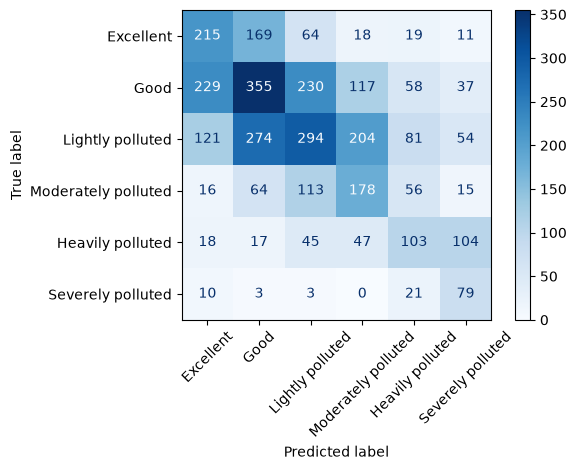

In [41]:
pred=model.predict(X_test); majority=y_train.value_counts().idxmax(); baseline=np.repeat(majority,len(y_test))
metrics={"accuracy":accuracy_score(y_test,pred),"precision_macro":precision_score(y_test,pred,average="macro",zero_division=0),"recall_macro":recall_score(y_test,pred,average="macro",zero_division=0),"f1_macro":f1_score(y_test,pred,average="macro",zero_division=0),"baseline_accuracy":accuracy_score(y_test,baseline),"baseline_f1_macro":f1_score(y_test,baseline,average="macro",zero_division=0)}
metrics["aqi_mae"]=mean_absolute_error(test.target_AQI,aqi_regressor.predict(X_test))
metrics["main_pollutant_accuracy"]=accuracy_score(test.target_main_pollutant,primary_pollutant_model.predict(X_test))
display(pd.Series(metrics).round(4))
labels=[c for c in CATEGORY_LABELS if c in set(y_train)|set(y_test)]
print(classification_report(y_test,pred,labels=labels,target_names=labels,zero_division=0,digits=3))
cm=confusion_matrix(y_test,pred,labels=labels)
display(pd.DataFrame(cm,index=["Actual "+x for x in labels],columns=["Predicted "+x for x in labels]))
ConfusionMatrixDisplay(cm,display_labels=labels).plot(cmap="Blues",xticks_rotation=45,values_format="d"); plt.tight_layout(); plt.show()

## 5. Reusable prediction function

Inputs must be **completed same-day pollutant summaries**, not instantaneous readings: 24-hour means for PM2.5, PM10, SO2, NO2 and CO, and daily maximum rolling 8-hour O3 mean. Units are µg/m³ except CO, mg/m³ (convert hourly source CO from µg/m³ by multiplying by 0.001). O3 is the daily maximum trailing 8-hour mean with >=6 valid observations per window and >=14 valid windows ending 08:00–23:00. The backend must compute these same windows before calling the function.

In [42]:
def predict_next_day_aqi(pm25,pm10,so2,no2,co,o3):
    """Predict tomorrow from today's six completed pollutant summaries.
    Pollutants: 24-hour means except O3 (daily max trailing 8-hour mean);
    CO is mg/m³, other pollutants µg/m³.
    """
    row=pd.DataFrame([[pm25,pm10,so2,no2,co,o3]],columns=FEATURES)
    values=[pm25,pm10,so2,no2,co,o3]
    if not np.isfinite(np.asarray(values,dtype=float)).all():
        raise ValueError("All pollutant inputs must be finite numbers")
    if any(float(value)<0 for value in values):
        raise ValueError("Pollutant inputs must be non-negative")
    probs=model.predict_proba(row)[0]
    c=model.classes_[int(np.argmax(probs))]
    predicted_aqi=int(np.clip(np.ceil(aqi_regressor.predict(row)[0]),0,500))
    main_pollutant=primary_pollutant_model.predict(row)[0]
    return {"predicted_category":c,"predicted_aqi":predicted_aqi,"predicted_main_pollutant":main_pollutant,"horizon":"next calendar day","standard":AQI_STANDARD}
predict_next_day_aqi(35,70,8,30,.7,110)

{'predicted_category': 'Good',
 'predicted_aqi': 101,
 'predicted_main_pollutant': 'PM2.5',
 'horizon': 'next calendar day',
 'standard': 'HJ 633—2026 (effective 2026-03-01; breakpoints match sets.ipynb and the provided table)'}

## 6. Save fitted model with requirements and evaluation


In [43]:
artifact={"model":model,"aqi_regressor":aqi_regressor,"primary_pollutant_model":primary_pollutant_model,"feature_requirements":{"features_in_order":FEATURES,"numeric_features":FEATURES,"units":{"PM2.5":"µg/m³","PM10":"µg/m³","SO2":"µg/m³","NO2":"µg/m³","CO":"mg/m³ (source µg/m³ converted by 0.001)","O3":"µg/m³"},"averaging_periods":{"PM2.5":"same-day 24-hour mean","PM10":"same-day 24-hour mean","SO2":"same-day 24-hour mean","NO2":"same-day 24-hour mean","CO":"same-day 24-hour mean","O3":"same-day maximum trailing 8-hour mean; at least six valid hours per window and 14 valid windows ending 08:00–23:00"}},"aqi_standard":AQI_STANDARD,"standard_source":"https://www.mee.gov.cn/ywgz/fgbz/bz/bzwb/jcffbz/202602/t20260225_1144441.shtml","category_mapping":{str(i):{"label":c} for i,c in enumerate(CATEGORY_LABELS,start=1)},"evaluation_metrics":{k:float(v) for k,v in metrics.items()},"training_period":[str(train.date.min().date()),str(train.date.max().date())],"test_period":[str(test.date.min().date()),str(test.date.max().date())],"best_parameters":search.best_params_,"sklearn_version":sklearn.__version__}
model_path=Path.cwd()/"aqi_next_day_random_forest.joblib"
joblib.dump(artifact,model_path)
print("Saved:",model_path.resolve(),"size MB:",round(model_path.stat().st_size/1e6,2))

Saved: C:\Users\PLP\Downloads\Data_Science\aqi_next_day_random_forest.joblib size MB: 586.77


## 7. Findings, limitations, web integration

Use the held-out scores, class supports and confusion matrix above to assess performance against the majority baseline. Macro scores weight each class equally; accuracy can conceal poor rare-class recall.

**Limitations:** 2013–2017 Beijing observations may not generalize to current conditions, other cities, or sensors. There are no weather forecasts, seasonal/calendar features, or lagged AQI. Classes are imbalanced and ordinal, while this classifier treats them nominally. Labels are recomputed retrospectively under HJ 633—2026. The stated completeness filters are simplified; validate monitor quality and aggregation against HJ 633—2026, HJ 663, and monitoring QA requirements before operational or health use.

**Web integration:** Load the joblib artifact at backend startup, aggregate hourly inputs using the exact documented units/windows, validate completeness, then return predicted category and probabilities with date and standard metadata. Monitor input drift and retrain on recent data. Do not present predictions as official AQI reports.